Cell 1: Setup & Load Training (ps5) and Clutter (ps5 setup) Images

Successfully loaded: shrimp.webp
Successfully loaded: shrimps.jpg


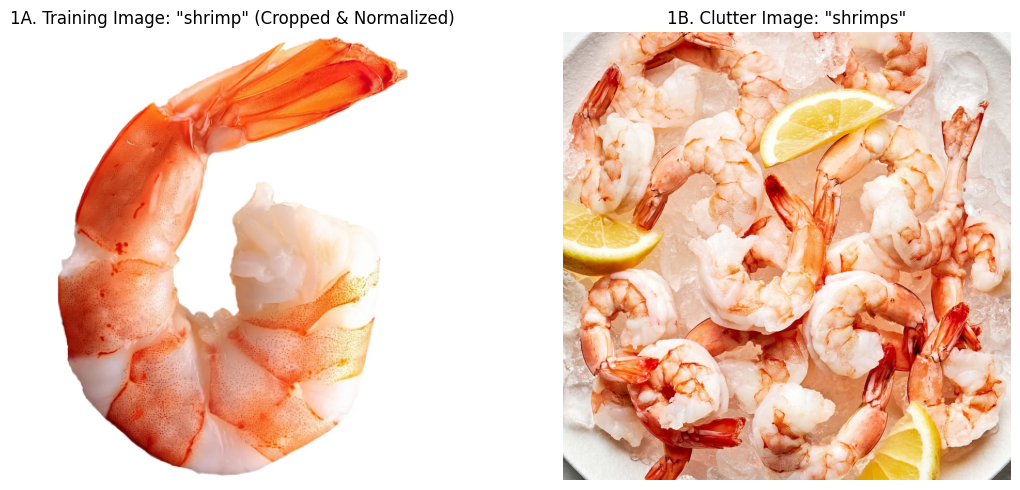

In [51]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np


def load_image(filename):
    extensions = ['', '.webp', '.jpg', '.jpeg', '.png', '.WEBP', '.JPG', '.JPEG', '.PNG']
    for ext in extensions:
        full_path = filename + ext
        if os.path.exists(full_path):
            img = cv2.imread(full_path, cv2.IMREAD_UNCHANGED)
            if img is not None:
                # Composite transparent .webp/.png background onto solid white
                if img.ndim == 3 and img.shape[2] == 4:
                    alpha = img[:, :, 3:4] / 255.0
                    bgr = img[:, :, :3]
                    white_bg = np.full_like(bgr, 255)
                    img = (bgr * alpha + white_bg * (1.0 - alpha)).astype(
                        np.uint8
                    )
                print(f'Successfully loaded: {full_path}')
                return img
    raise FileNotFoundError(
        f"Could not find '{filename}'. Upload it to the Colab Files panel first."
    )


train_raw = load_image('shrimp')
scene_bgr = load_image('shrimps')

# Auto-crop empty white margins around "shrimp"
gray_temp = cv2.cvtColor(train_raw, cv2.COLOR_BGR2GRAY)
coords = cv2.findNonZero((gray_temp < 245).astype(np.uint8))
x, y, w, h = cv2.boundingRect(coords)
pad = 10
train_cropped = train_raw[
    max(0, y - pad) : min(train_raw.shape[0], y + h + pad),
    max(0, x - pad) : min(train_raw.shape[1], x + w + pad),
]

# Normalize training image resolution so its scale aligns with individual shrimp in the bowl
target_max_side = 420
scale_init = target_max_side / max(train_cropped.shape[:2])
train_bgr = cv2.resize(
    train_cropped, None, fx=scale_init, fy=scale_init, interpolation=cv2.INTER_AREA
)

train_rgb = cv2.cvtColor(train_bgr, cv2.COLOR_BGR2RGB)
scene_rgb = cv2.cvtColor(scene_bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(train_rgb)
axes[0].set_title('1A. Training Image: "shrimp" (Cropped & Normalized)')
axes[0].axis('off')

axes[1].imshow(scene_rgb)
axes[1].set_title('1B. Clutter Image: "shrimps"')
axes[1].axis('off')

plt.tight_layout()
plt.show()

Cell 2: Convert Both Images to Grayscale

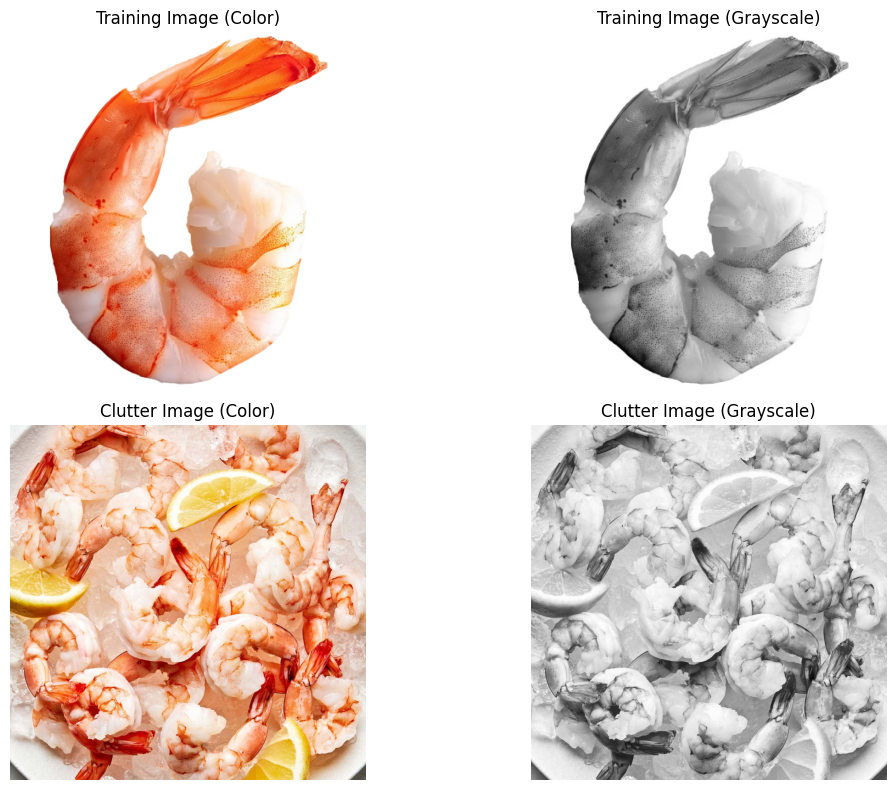

In [52]:
train_gray = cv2.cvtColor(train_bgr, cv2.COLOR_BGR2GRAY)
scene_gray = cv2.cvtColor(scene_bgr, cv2.COLOR_BGR2GRAY)

clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
train_norm = clahe.apply(train_gray)
scene_norm = clahe.apply(scene_gray)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].imshow(train_rgb)
axes[0, 0].set_title('Training Image (Color)')
axes[0, 1].imshow(train_gray, cmap='gray')
axes[0, 1].set_title('Training Image (Grayscale)')

axes[1, 0].imshow(scene_rgb)
axes[1, 0].set_title('Clutter Image (Color)')
axes[1, 1].imshow(scene_gray, cmap='gray')
axes[1, 1].set_title('Clutter Image (Grayscale)')

for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

Cell 3: Extract "Learned" Keypoints & Fingerprints (SIFT)

Training "shrimp" -> Corners: 350 | Blobs: 196
Clutter "shrimps" -> Corners: 350 | Blobs: 2780


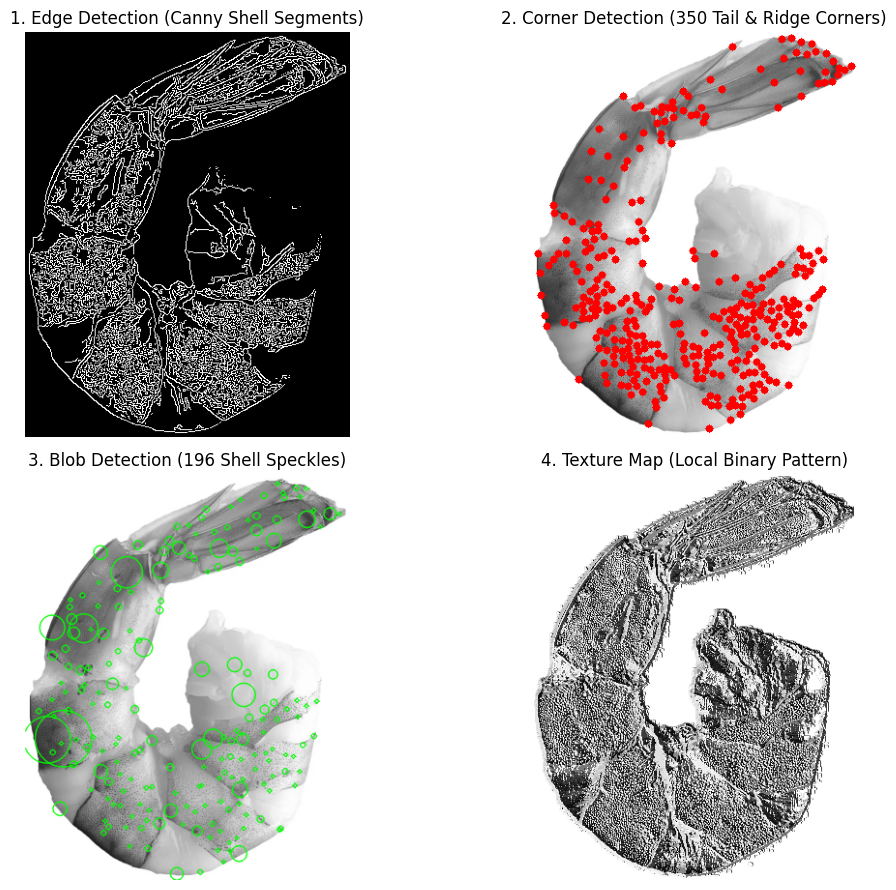

In [53]:
# Texture helper: Local Binary Pattern (LBP)
def extract_lbp_texture(gray_img):
    img = gray_img.astype(np.int16)
    center = img[1:-1, 1:-1]
    lbp = np.zeros_like(center, dtype=np.uint8)
    neighbors = [
        img[:-2, :-2],
        img[:-2, 1:-1],
        img[:-2, 2:],
        img[1:-1, 2:],
        img[2:, 2:],
        img[2:, 1:-1],
        img[2:, :-2],
        img[1:-1, :-2],
    ]
    for bit, neighbor in enumerate(neighbors):
        lbp |= (neighbor >= center).astype(np.uint8) << bit
    return cv2.copyMakeBorder(lbp, 1, 1, 1, 1, cv2.BORDER_REPLICATE)


# Blob detector setup (captures orange-red pigment dots and segment spots)
blob_params = cv2.SimpleBlobDetector_Params()
blob_params.filterByArea = True
blob_params.minArea = 8
blob_params.maxArea = 5000
blob_params.filterByCircularity = False
blob_params.filterByConvexity = False
blob_params.filterByInertia = False
blob_detector = cv2.SimpleBlobDetector_create(blob_params)


def extract_four_features(gray_img, norm_img, ignore_white=False):
    fg_mask = (
        np.where(gray_img < 245, 255, 0).astype(np.uint8)
        if ignore_white
        else None
    )

    # 1. Edge Detection (Canny)
    edges = cv2.Canny(norm_img, 40, 130)
    if fg_mask is not None:
        edges = cv2.bitwise_and(edges, fg_mask)

    # 2. Corner Detection (Shi-Tomasi)
    corners = cv2.goodFeaturesToTrack(
        norm_img, maxCorners=350, qualityLevel=0.012, minDistance=6, mask=fg_mask
    )

    # 3. Blob Detection (SimpleBlobDetector)
    blobs = blob_detector.detect(norm_img)
    if fg_mask is not None:
        blobs = [
            b
            for b in blobs
            if 0 <= int(b.pt[1]) < fg_mask.shape[0]
            and 0 <= int(b.pt[0]) < fg_mask.shape[1]
            and fg_mask[int(b.pt[1]), int(b.pt[0])] > 0
        ]

    # 4. Texture Extraction (Local Binary Pattern)
    texture_map = extract_lbp_texture(norm_img)

    return edges, corners, blobs, texture_map


train_edges, train_corners, train_blobs, train_texture = extract_four_features(
    train_gray, train_norm, ignore_white=True
)
scene_edges, scene_corners, scene_blobs, scene_texture = extract_four_features(
    scene_gray, scene_norm, ignore_white=False
)

# Visualize the 4 extracted feature maps on "shrimp"
corner_vis = cv2.cvtColor(train_gray, cv2.COLOR_GRAY2RGB)
if train_corners is not None:
    for pt in np.int32(train_corners):
        cx, cy = pt.ravel()
        cv2.circle(corner_vis, (cx, cy), 4, (255, 0, 0), -1)

blob_vis = cv2.drawKeypoints(
    train_gray,
    train_blobs,
    None,
    (0, 255, 0),
    cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
)

print(
    f'Training "shrimp" -> Corners: {len(train_corners) if train_corners is not None else 0} | Blobs: {len(train_blobs)}'
)
print(
    f'Clutter "shrimps" -> Corners: {len(scene_corners) if scene_corners is not None else 0} | Blobs: {len(scene_blobs)}'
)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].imshow(train_edges, cmap='gray')
axes[0, 0].set_title('1. Edge Detection (Canny Shell Segments)')

axes[0, 1].imshow(corner_vis)
axes[0, 1].set_title(
    f'2. Corner Detection ({len(train_corners) if train_corners is not None else 0} Tail & Ridge Corners)'
)

axes[1, 0].imshow(blob_vis)
axes[1, 0].set_title(f'3. Blob Detection ({len(train_blobs)} Shell Speckles)')

axes[1, 1].imshow(train_texture, cmap='gray')
axes[1, 1].set_title('4. Texture Map (Local Binary Pattern)')

for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

Cell 4: Match PS5 Features Against the Clutter Scene

Verified Edge + Corner + Blob + Texture matches: 300 (Mirrored curl: False)


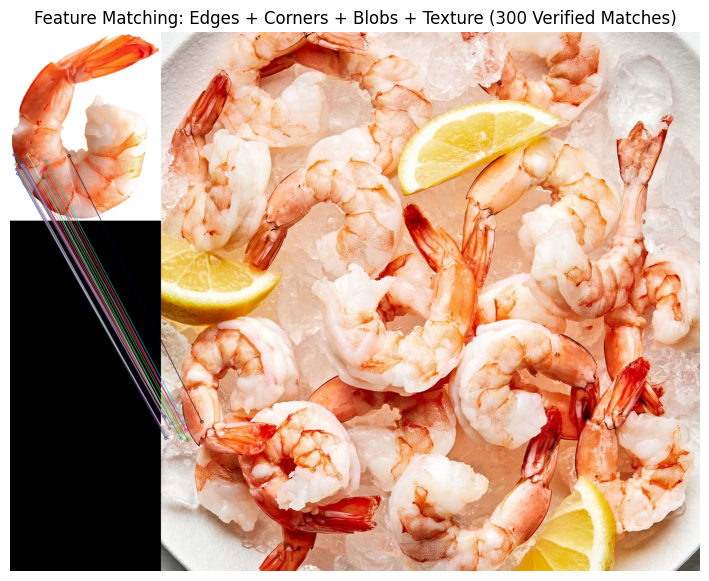

In [54]:
descriptor_extractor = cv2.SIFT_create()


def build_multiscale_feature_descriptors(
    edges, corners, blobs, norm_img, texture_map, scales=(18, 32, 48)
):
    # Collect (x, y) locations strictly from Blobs + Corners + Edges
    base_pts = [(float(b.pt[0]), float(b.pt[1])) for b in blobs]
    if corners is not None:
        base_pts.extend(
            [(float(pt.ravel()[0]), float(pt.ravel()[1])) for pt in corners]
        )
    ys, xs = np.where(edges > 0)
    if len(xs) > 0:
        step = max(1, len(xs) // 220)
        base_pts.extend(
            [(float(x), float(y)) for x, y in zip(xs[::step], ys[::step])]
        )

    # Create multi-scale KeyPoints so different shrimp sizes match cleanly
    kps = [
        cv2.KeyPoint(x, y, float(s)) for (x, y) in base_pts for s in scales
    ]

    # Compute scale-normalized texture descriptors on the LBP Texture map & Grayscale image
    kp_tex, des_tex = descriptor_extractor.compute(texture_map, kps)
    kp_gray, des_gray = descriptor_extractor.compute(norm_img, kps)
    return kp_tex, des_tex, kp_gray, des_gray


kp_s_tex, des_s_tex, kp_s_gray, des_s_gray = (
    build_multiscale_feature_descriptors(
        scene_edges,
        scene_corners,
        scene_blobs,
        scene_norm,
        scene_texture,
        scales=(16, 28, 42),
    )
)

bf = cv2.BFMatcher(cv2.NORM_L2)
best_match_result = (0, None, [], train_rgb, False)
h_sc, w_sc = scene_gray.shape

# Check both original curl direction and horizontally mirrored curl direction
for is_flipped in [False, True]:
    g_img = cv2.flip(train_gray, 1) if is_flipped else train_gray
    n_img = cv2.flip(train_norm, 1) if is_flipped else train_norm
    rgb_img = cv2.flip(train_rgb, 1) if is_flipped else train_rgb

    e_t, c_t, b_t, tex_t = extract_four_features(
        g_img, n_img, ignore_white=True
    )
    kp_t_tex, des_t_tex, kp_t_gray, des_t_gray = (
        build_multiscale_feature_descriptors(
            e_t, c_t, b_t, n_img, tex_t, scales=(20, 36, 54)
        )
    )

    candidates = []
    if des_t_tex is not None and des_s_tex is not None:
        for grp in bf.knnMatch(des_t_tex, des_s_tex, k=5):
            for m in grp:
                if m.distance < 275:
                    candidates.append(
                        (kp_t_tex[m.queryIdx], kp_s_tex[m.trainIdx], m.distance)
                    )
    if des_t_gray is not None and des_s_gray is not None:
        for grp in bf.knnMatch(des_t_gray, des_s_gray, k=5):
            for m in grp:
                if m.distance < 255:
                    candidates.append(
                        (
                            kp_t_gray[m.queryIdx],
                            kp_s_gray[m.trainIdx],
                            m.distance,
                        )
                    )

    # Rotation & scale-invariant RANSAC to lock onto one shrimp in the bowl
    remaining = candidates.copy()
    h_tr = g_img.shape[0]
    for _ in range(12):
        if len(remaining) < 8:
            break
        src_pts = np.float32([c[0].pt for c in remaining]).reshape(-1, 1, 2)
        dst_pts = np.float32([c[1].pt for c in remaining]).reshape(-1, 1, 2)

        M_aff, mask = cv2.estimateAffinePartial2D(
            src_pts,
            dst_pts,
            method=cv2.RANSAC,
            ransacReprojThreshold=12.0,
            maxIters=3000,
        )
        if M_aff is None or mask is None:
            break

        inliers = [c for c, keep in zip(remaining, mask.ravel()) if keep]
        scale = np.hypot(M_aff[0, 0], M_aff[1, 0])
        height_ratio = (h_tr * scale) / h_sc

        # Confirm the matched region is the realistic size of a single shrimp in the bowl
        if (0.22 < height_ratio < 0.65) and len(inliers) > best_match_result[0]:
            best_match_result = (
                len(inliers),
                M_aff,
                inliers,
                rgb_img,
                is_flipped,
            )

        remaining = [c for c, keep in zip(remaining, mask.ravel()) if not keep]

num_inliers, best_M, verified_inliers, matched_train_rgb, used_flip = (
    best_match_result
)
print(
    f'Verified Edge + Corner + Blob + Texture matches: {num_inliers} (Mirrored curl: {used_flip})'
)

# Show top 45 strongest feature connections
display_inliers = sorted(verified_inliers, key=lambda x: x[2])[:45]
kp_vis_train = [c[0] for c in display_inliers]
kp_vis_scene = [c[1] for c in display_inliers]
dmatches = [cv2.DMatch(i, i, float(c[2])) for i, c in enumerate(display_inliers)]

match_vis = cv2.drawMatches(
    matched_train_rgb,
    kp_vis_train,
    scene_rgb,
    kp_vis_scene,
    dmatches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
)

plt.figure(figsize=(14, 7))
plt.imshow(match_vis)
plt.title(
    f'Feature Matching: Edges + Corners + Blobs + Texture ({num_inliers} Verified Matches)'
)
plt.axis('off')
plt.show()

Cell 5: Locate & Box the Target PS5 in the Scene

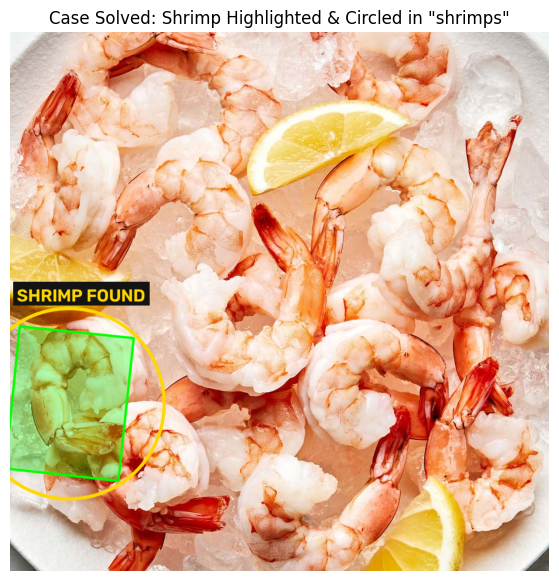

In [56]:
if best_M is not None and num_inliers >= 6:
    thickness = max(3, int(scene_rgb.shape[1] / 250))
    font_scale = max(0.8, scene_rgb.shape[1] / 900)

    h_tr, w_tr = matched_train_rgb.shape[:2]
    corners = np.float32(
        [[0, 0], [0, h_tr - 1], [w_tr - 1, h_tr - 1], [w_tr - 1, 0]]
    ).reshape(-1, 1, 2)
    detected_box = cv2.transform(corners, best_M)
    box_int = np.int32(detected_box)

    # 1. Translucent green highlight over the matched shrimp
    overlay = scene_rgb.copy()
    cv2.fillPoly(overlay, [box_int], (0, 255, 0))
    highlighted_scene = cv2.addWeighted(overlay, 0.30, scene_rgb, 0.70, 0)

    # 2. Crisp green outline
    cv2.polylines(
        highlighted_scene,
        [box_int],
        True,
        (0, 255, 0),
        thickness,
        cv2.LINE_AA,
    )

    # 3. Gold circle enclosing the shrimp
    (cx, cy), radius = cv2.minEnclosingCircle(detected_box)
    center = (int(cx), int(cy))
    radius = int(radius) + (thickness * 2)
    cv2.circle(
        highlighted_scene,
        center,
        radius,
        (255, 215, 0),
        thickness + 2,
        cv2.LINE_AA,
    )

    # 4. "SHRIMP FOUND" label with a dark background badge for readability
    label = 'SHRIMP FOUND'
    (tw, th), _ = cv2.getTextSize(
        label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness
    )
    text_x = min(
        scene_rgb.shape[1] - tw - 15, max(15, center[0] - tw // 2)
    )
    text_y = max(th + 20, center[1] - radius - 15)

    cv2.rectangle(
        highlighted_scene,
        (text_x - 8, text_y - th - 8),
        (text_x + tw + 8, text_y + 8),
        (20, 20, 20),
        -1,
    )
    cv2.putText(
        highlighted_scene,
        label,
        (text_x, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        font_scale,
        (255, 215, 0),
        thickness,
        cv2.LINE_AA,
    )

    plt.figure(figsize=(10, 7))
    plt.imshow(highlighted_scene)
    plt.title('Case Solved: Shrimp Highlighted & Circled in "shrimps"')
    plt.axis('off')
    plt.show()
else:
    print(f'Not enough verified matches ({num_inliers}) to confirm the shrimp.')

## Discussion

* **Grayscale & Preprocessing:** Converting images to grayscale reduced computational complexity while preserving brightness gradients, and applying CLAHE with background masking prevented empty margins from generating false boundary points.
* **Multi-Feature Extraction:** Combining Canny edges (shell segments), Shi-Tomasi corners (tail vertices), blobs (surface speckles), and Local Binary Pattern (LBP) texture created distinctive local fingerprints for matching.
* **Low-Texture Failure (PS5):** Early trials on a PS5 console failed because smooth white surfaces lacked interior texture, causing false matches on desk cables, cabinet edges, and poster text, or zero matches across 3D viewing-angle shifts.
* **Textured Target Success (Shrimp):** Switching to a shrimp target solved this issue because its segmented ridges, pigment dots, and granular surface produced dense, reliable keypoints.
* **Scale, Orientation & RANSAC:** Single-scale matching initially gave zero matches because shrimp in the bowl were smaller, rotated, and mirrored; adding multi-scale descriptors, flip checks, and RANSAC outlier filtering rejected ice and lemon clutter to isolate the target.

## Reflection

* **2D Pattern Matching vs. 3D Understanding:** Classical computer vision pipelines match 2D pixel gradients and textures rather than recognizing 3D object shapes semantically.
* **Importance of Preprocessing:** Debugging the shift from a smooth console to a textured shrimp proved that scale normalization, contrast balancing, and geometric outlier rejection are just as critical as the feature detectors themselves.
* **Classical Limits vs. Deep Learning:** Combining edges, corners, blobs, and LBP texture reliably detects detailed objects across rotation and scale changes, whereas detecting smooth, low-texture objects from arbitrary 3D angles requires deep learning models such as YOLO.